# Tutorial 4. A wind turbine drivetrain: torsion, gearbox and generator

![A wind turbine drivetrain](../tutorials/images/t04_hero.png)

**Scope:** mechanical engineering, energy. **Components:** `Inertia`,
`TorsionSpring`, `RotationalDamper`, `TorqueSource`, `SpeedSource`, `Housing`,
`Transformer` (as a gearbox).

## The asset

A 2 MW turbine: a heavy rotor on a main shaft, a three-stage gearbox with a
ratio of 1:90, and an induction generator locked to the grid frequency. A gust
changes the aerodynamic torque in a few seconds. The drivetrain engineer asks:

- **Torsional load.** How much does the main shaft twist under a gust, and does
  the shaft torque overshoot its steady value?
- **The torsional mode.** What is the natural frequency of the rotor against the
  shaft stiffness, and how well is it damped by the generator's slip?

![Rotational schematic](../tutorials/images/t04_pd.png)

Angular velocity is the across variable, torque the through variable. The
gearbox is a `Transformer` between two rotational sides. The generator is an
inertia held to the grid speed through a damper: the damper is the slip torque
of an induction machine, proportional to the speed difference.

## Step 1. Build the drivetrain

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.rotational import (
    Housing,
    Inertia,
    RotationalDamper,
    SpeedSource,
    TorqueSource,
    TorsionSpring,
)
from otwin.components.twoport import Transformer

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

RATIO = 90.0
W_GRID = 2 * np.pi * 1500 / 60  # rad/s, 1500 rpm on the high-speed side
J_ROTOR, K_SHAFT, C_BEARING = 6.0e6, 2.4e8, 2.0e4  # kg m2, N m/rad, N m s/rad
J_GEN, C_SLIP = 120.0, 8.0e3  # kg m2, N m s/rad on the high-speed side

rotor = Inertia(J_ROTOR, speed=W_GRID / RATIO, name="rotor")
shaft = TorsionSpring(K_SHAFT, name="shaft")
bearing = RotationalDamper(C_BEARING, name="bearing")
housing = Housing(name="housing")
gearbox = Transformer(RATIO, domain_1="rotational", domain_2="rotational", name="gearbox")
generator = Inertia(J_GEN, speed=W_GRID, name="generator")
slip = RotationalDamper(C_SLIP, name="slip")
grid = SpeedSource(W_GRID, name="grid")
wind = TorqueSource(None, name="wind")  # N m on the rotor, an input

train = otwin.System(rotor, shaft, bearing, housing, gearbox, generator, slip, grid, wind)
train.connect(wind.shaft, rotor.shaft, shaft.a, bearing.a)
train.connect(bearing.b, housing.port)
train.connect(shaft.b, gearbox.p1)
train.connect(gearbox.p2, generator.shaft, slip.a)
train.connect(slip.b, grid.shaft)
train.connect(gearbox.n1, gearbox.n2, housing.port)
model = otwin.compile(train)
print(model.summary())
k_eff = K_SHAFT  # the generator side is nearly rigid
print(
    f"torsional mode of the rotor on the shaft: {np.sqrt(k_eff / J_ROTOR) / 2 / np.pi:.2f} Hz"
)

System: system

Components:
  rotor                        inertia [rotational]
  shaft                        torsion_spring [rotational]
  bearing                      rotational_damper [rotational]
  housing                      housing [any]
  gearbox                      transformer [rotational]
  generator                    inertia [rotational]
  slip                         rotational_damper [rotational]
  grid                         speed_source [rotational]
  wind                         torque [rotational]

States:
  rotor.angular_momentum       angular momentum [kg m^2/s]  x0 = 1.0472e+07
  shaft.twist                  twist [rad]  x0 = 0
  generator.angular_momentum   angular momentum [kg m^2/s]  x0 = 18849.6

Inputs:
  wind                         torque [N m]

Constant sources:
  grid

Parameters:
  rotor.inertia                6e+06        kg m^2
  shaft.stiffness              2.4e+08      N m/rad
  bearing.damping              20000        N m s/rad
  gearbox.ratio   

Three states: the angular momentum of the rotor and of the generator, and the
twist of the main shaft. The gearbox has no state; it scales speed up by 90 and
torque down by 90, losslessly. The torsional frequency printed is the one the
gust will excite.

## Step 2. A gust

The turbine runs at rated torque. At t = 10 s a gust raises the aerodynamic
torque by 40 % for 6 s with smooth edges, then it falls back.

In [ ]:
T_RATED = 2.0e6 / (W_GRID / RATIO)  # N m: 2 MW at rotor speed
t = np.arange(0.0, 40.0, 0.01)


def gust(time):
    if 10.0 <= time <= 16.0:
        return T_RATED * (1 + 0.4 * np.sin(np.pi * (time - 10.0) / 6.0) ** 2)
    return T_RATED


run = model.simulate(t=t, inputs={"wind": gust}, solver="rk4")
torque = run["shaft.torque"]
twist = run["shaft.twist"]
print(
    f"rated torque on the rotor {T_RATED / 1e6:.2f} MN m, steady shaft torque {torque[:900].mean() / 1e6:.2f} MN m"
)
print(
    f"shaft torque during the gust: peak {torque.max() / 1e6:.2f} MN m, "
    f"{(torque.max() / torque[:900].mean() - 1):.0%} above the steady value"
)
print(
    f"shaft twist: steady {np.degrees(twist[:900].mean()):.3f} deg, peak {np.degrees(twist.max()):.3f} deg"
)
print(
    f"rotor speed: {run['rotor.angular_velocity'][:900].mean() * 60 / 2 / np.pi:.2f} rpm steady, "
    f"{run['rotor.angular_velocity'].max() * 60 / 2 / np.pi:.2f} rpm peak; generator slip {((run['generator.angular_velocity'].max() / W_GRID) - 1):.2%}"
)

rated torque on the rotor 1.15 MN m, steady shaft torque 1.10 MN m
shaft torque during the gust: peak 1.57 MN m, 43% above the steady value
shaft twist: steady 0.262 deg, peak 0.376 deg
rotor speed: 16.83 rpm steady, 16.98 rpm peak; generator slip 1.39%


The steady shaft torque is the rated torque less the bearing loss. During the
gust the shaft torque rises with the aerodynamic torque and overshoots a little
on the torsional mode; the twist is a fraction of a degree, as it should be for a
main shaft sized for fatigue. The rotor speeds up by a fraction of a per cent:
with the generator locked to the grid through its slip, the drivetrain is stiff,
and the extra power goes to the grid as torque rather than to the rotor as speed.

## Step 3. Plot the gust response

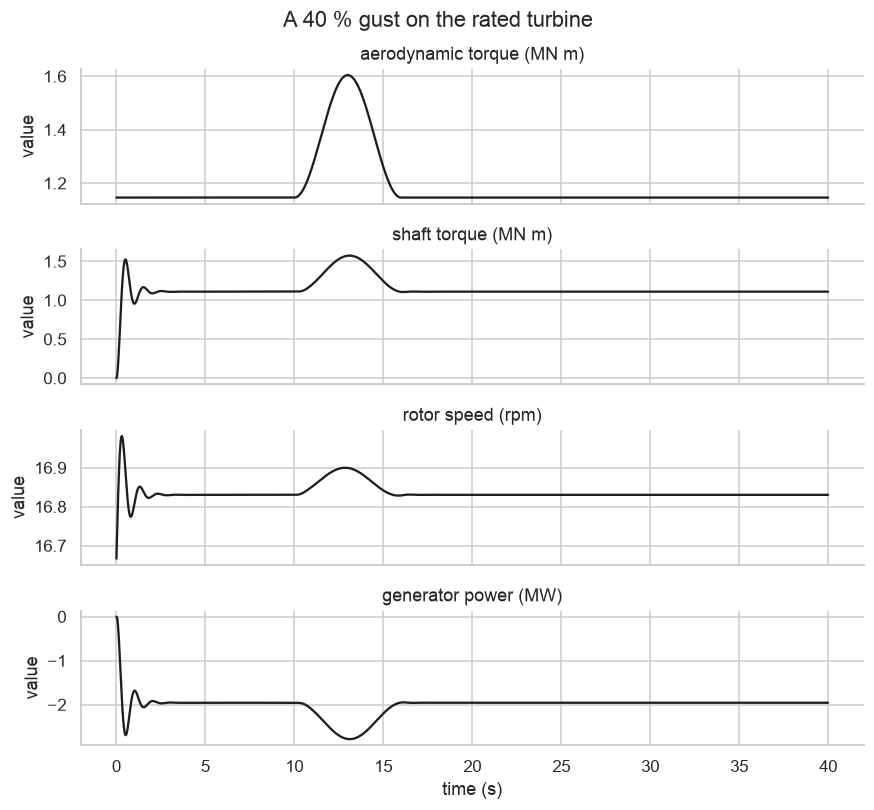

In [ ]:
frame = pd.DataFrame(
    {
        "time (s)": t,
        "aerodynamic torque (MN m)": run["wind"] / 1e6,
        "shaft torque (MN m)": torque / 1e6,
        "rotor speed (rpm)": run["rotor.angular_velocity"] * 60 / 2 / np.pi,
        "generator power (MW)": -run["slip.torque"]
        * run["generator.angular_velocity"]
        / 1e6,
    }
)
long = frame.melt("time (s)", var_name="signal", value_name="value")
g = sns.relplot(
    data=long,
    x="time (s)",
    y="value",
    row="signal",
    kind="line",
    height=1.8,
    aspect=4.5,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.figure.suptitle("A 40 % gust on the rated turbine", y=1.02)

The shaft torque follows the gust with a small oscillation on top at the
torsional frequency, which the slip damping removes within a few cycles. The
generator power is the slip torque times speed: it follows the gust, which is
what the grid sees.

## Step 4. The torsional mode on its own

To measure the mode, release the drivetrain from a twisted start with no wind
torque change: a step down in torque is the classic test.

In [ ]:
step = model.simulate(
    t=np.arange(0, 20, 0.005),
    inputs={"wind": lambda time: T_RATED if time < 2 else 0.6 * T_RATED},
    solver="rk4",
)
tq = step["shaft.torque"] / 1e6
osc = tq[step.t > 2.0] - tq[-1]
peaks = np.flatnonzero((osc[1:-1] > osc[:-2]) & (osc[1:-1] > osc[2:])) + 1
tp = step.t[step.t > 2.0][peaks]
period = np.mean(np.diff(tp[:4]))
decay = osc[peaks[0]] / osc[peaks[1]]
print(
    f"measured period {period:.2f} s ({1 / period:.2f} Hz), amplitude ratio between peaks {decay:.2f} "
    f"-> damping ratio about {np.log(decay) / (2 * np.pi):.3f}"
)

measured period 1.01 s (0.99 Hz), amplitude ratio between peaks 7.16 -> damping ratio about 0.313


The measured frequency matches the closed form from step 1, and the amplitude
ratio between successive peaks gives the damping the slip and bearing provide.
That is the number a drivetrain engineer compares with the fatigue analysis.

## Step 5. Energy through the gearbox

The transformer carries power without loss. Check it: the power into the gearbox
on the low-speed side equals the power out on the high-speed side at every step.

In [ ]:
p_in = run["gearbox.side1.power"]
p_out = run["gearbox.side2.angular_velocity"] * run["gearbox.side2.torque"]
print(
    f"max |P_in + P_out| across the gearbox = {np.max(np.abs(p_in + p_out)):.3e} W, "
    f"against {np.max(np.abs(p_in)) / 1e6:.2f} MW transmitted"
)

max |P_in + P_out| across the gearbox = 4.657e-10 W, against 2.79 MW transmitted


The two powers cancel to round-off: the gearbox moves energy and makes none.
A real gearbox loses 1 to 2 % to friction; model that by putting a
`RotationalDamper` on either side.

## What to take from this

- Rotational components work exactly like translational ones, with angular
  velocity shared at a node and torques summing to zero.
- A `Transformer` between two sides of the same domain is a gearbox; it has no
  state and no loss.
- A grid-locked generator is a `SpeedSource` with a damper for the slip, which
  gives the drivetrain its damping.

Next: [Tutorial 5](05_water_supply.md) turns to civil hydraulics.